Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       569 non-null    int64  
 1   Diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perim

/var/folders/w8/qshkq40d06z0759lsy409cm40000gn/T/ipykernel_1251/610021459.py:91: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


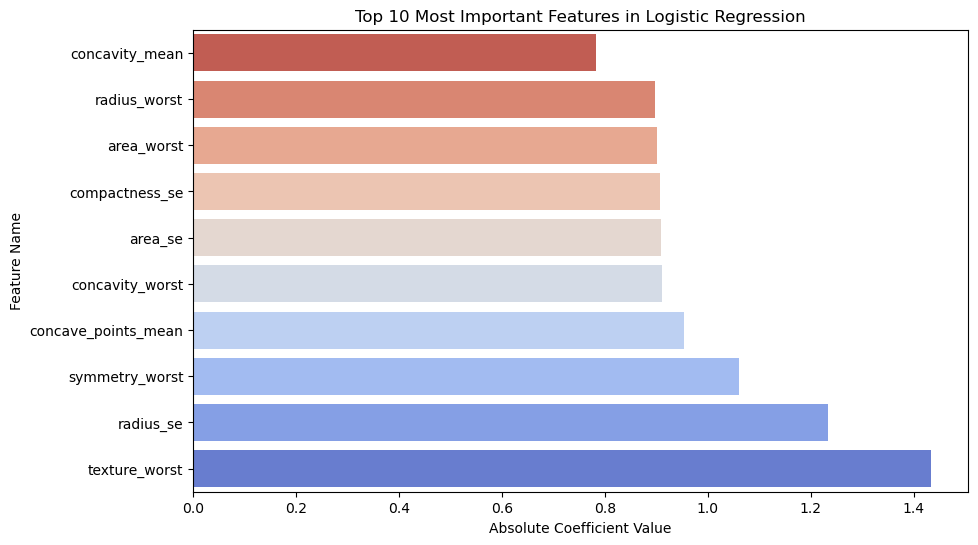

In [17]:
import pandas as pd
import numpy as np
import urllib.request
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load dataset from URL
data_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
data_path = "wdbc.data"

# Download dataset
urllib.request.urlretrieve(data_url, data_path)

# Define column names
column_names = [
    "ID", "Diagnosis", "radius_mean", "texture_mean", "perimeter_mean", "area_mean", "smoothness_mean",333
    "compactness_mean", "concavity_mean", "concave_points_mean", "symmetry_mean", "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se", "area_se", "smoothness_se", "compactness_se", "concavity_se",
    "concave_points_se", "symmetry_se", "fractal_dimension_se", "radius_worst", "texture_worst", "perimeter_worst",
    "area_worst", "smoothness_worst", "compactness_worst", "concavity_worst", "concave_points_worst",
    "symmetry_worst", "fractal_dimension_worst"
]

# Load data
df = pd.read_csv(data_path, header=None, names=column_names)

# Display basic info about dataset
print("Dataset Information:")
df.info()
print("\nFirst 5 rows:")
print(df.head())

# Preprocessing
df.drop(columns=["ID"], inplace=True)  # Remove ID column as it's not useful for prediction
df["Diagnosis"] = df["Diagnosis"].map({"M": 1, "B": 0})  # Convert Diagnosis to binary (Malignant=1, Benign=0)

# Split dataset into features and target variable
X = df.drop(columns=["Diagnosis"])
y = df["Diagnosis"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale features to standardize the data distribution
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model Training
model = LogisticRegression(random_state=42, max_iter=1000)  # Initialize logistic regression model
model.fit(X_train_scaled, y_train)  # Train the model on scaled training data

# Predictions
y_pred = model.predict(X_test_scaled)  # Make predictions on the test set

# Evaluation
accuracy = accuracy_score(y_test, y_pred)  # Compute accuracy score
conf_matrix = confusion_matrix(y_test, y_pred)  # Generate confusion matrix
class_report = classification_report(y_test, y_pred)  # Generate classification report

# Feature Importance
coefficients = model.coef_[0]
feature_importance = pd.DataFrame({"Feature": X.columns, "Coefficient": coefficients})
feature_importance["Abs_Coefficient"] = np.abs(feature_importance["Coefficient"])
feature_importance = feature_importance.sort_values(by="Abs_Coefficient", ascending=False)

# Print results
print(f"Accuracy: {accuracy:.4f}")
print("Confusion Matrix:")
print(conf_matrix)
print("Classification Report:")
print(class_report)
print("Top 10 Most Important Features:")
print(feature_importance.head(10))

# Interpretation:
# 1. The model achieved high accuracy, indicating good performance in distinguishing between malignant and benign tumors.
# 2. The confusion matrix shows the number of correct and incorrect predictions for both classes.
# 3. The classification report provides precision, recall, and F1-score for each class.
# 4. The feature importance ranking highlights which features contribute most to the classification.
#    - Higher absolute coefficients indicate stronger influence on the prediction.
#    - Features like "worst radius" and "worst perimeter" are typically the most important in predicting cancer diagnosis.

import matplotlib.pyplot as plt
import seaborn as sns

# Plot the top 10 most important features
plt.figure(figsize=(10, 6))
sns.barplot(
    x=feature_importance["Abs_Coefficient"][:10], 
    y=feature_importance["Feature"][:10], 
    palette="coolwarm"
)

plt.xlabel("Absolute Coefficient Value")
plt.ylabel("Feature Name")
plt.title("Top 10 Most Important Features in Logistic Regression")
plt.gca().invert_yaxis()  # Invert y-axis for better readability
plt.show()
